<a href="https://colab.research.google.com/github/amasha-sinhalagoda/J26-IT-334/blob/model%2Fcp_landslide/ModelLandslide.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook builds and compares landslide prediction models for the Nuwara Eliya District in Sri Lanka. I use spatial cross-validation to test Logistic Regression, XGBoost, and LightGBM models. The dataset has 958 rows, split equally between 479 landslide events and 479 control points. My goal is to find the best model using trustworthy soil and terrain features while avoiding data leaks.

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import wilcoxon

SEED = 42
sns.set_theme(style="whitegrid")

DATA = None
OUT = None

for p in [Path("data/processed"), Path("../data/processed"), Path("data"), Path(".")]:
    f = p / "landslide_dynamic_ml_dataset_terrain.csv"
    if f.exists():
        DATA = f
        OUT = p.parent.parent / "outputs" / "tables" if p.name == "processed" else Path("outputs/tables")
        break

if DATA is None or OUT is None:
    raise FileNotFoundError("Could not find 'landslide_dynamic_ml_dataset_terrain.csv' in any of the searched paths. Please check your working directory or file structure.")

OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA)
print("Loaded:", DATA, df.shape)
print(df["dynamic_label"].value_counts().to_dict())
df.head(3)

Loaded: data/landslide_dynamic_ml_dataset_terrain.csv (958, 31)
{1: 479, 0: 479}


,sample_id,block_id,control_id,distance_to_static_km,dynamic_label,event_date,event_key,fold,lat,lon,...,soil_clay_60_100,soil_clay_gradient,soil_oc_0_30,soil_ph_0_30,soil_sand_0_30,soil_silt_0_30,static_index,static_susceptibility_label,elevation_m,slope_deg
0,sample_00000,67_72,NaN,0.346125,1,2025-11-27,7.15352_80.789_2025-11-27,3,7.153525,80.789001,...,28.72892,7.89976,1.51489,5.55341,57.88093,18.38064,4,1,974.0,17.622553
1,sample_00001,65_66,NaN,0.130755,1,2025-11-27,6.99376_80.74705_2025-11-27,3,6.993756,80.747054,...,29.25217,4.58613,2.30208,5.31695,51.73974,21.23204,7,1,1983.0,18.944181
2,sample_00002,67_65,NaN,0.080616,1,2025-11-27,6.96744_80.78311_2025-11-27,4,6.967445,80.783106,...,30.96726,5.48296,2.30459,5.26265,50.17258,22.22463,17,1,1889.0,11.461837


I loaded the dataset and checked its shape and class balance. There are 479 events and 479 controls, which means the classes are perfectly balanced.

*Step 2 – Remove leaky columns*

| Column | Why it must go |
|---|---|
| `distance_to_static_km` | Missing for **all** controls, present for all events → model just reads the missingness |
| `static_susceptibility_label` | Set to 0 for every control → label leak |
| `static_index` | A row ID, not a property of the terrain |
| `sample_id, block_id, control_id, event_key, event_date` | Identifiers |

`fold` is kept only to build the spatial CV splits (never as a feature).

Step 2: Removing leaky columns

I need to drop columns that contain information the model would not have in the real world. This step removes distance_to_static_km, static_susceptibility_label, and static_index because they leak the target label. I also remove other sample identifiers.

In [3]:
LEAKY = ["distance_to_static_km", "static_susceptibility_label", "static_index"]
IDS   = ["sample_id", "block_id", "control_id", "event_key", "event_date"]
df = df.drop(columns=LEAKY + IDS)
print("Remaining columns:", list(df.columns))
print("Missing values:", int(df.isna().sum().sum()))

Remaining columns: ['dynamic_label', 'fold', 'lat', 'lon', 'max_daily_rain_7d_mm', 'rain_14d_mm', 'rain_1d_mm', 'rain_30d_mm', 'rain_3d_mm', 'rain_7d_mm', 'rainfall_days_7d', 'soil_awc_0_30', 'soil_bd_0_30', 'soil_cec_0_30', 'soil_clay_0_30', 'soil_clay_60_100', 'soil_clay_gradient', 'soil_oc_0_30', 'soil_ph_0_30', 'soil_sand_0_30', 'soil_silt_0_30', 'elevation_m', 'slope_deg']
Missing values: 0


The leaky columns and identifiers are now removed. This leaves us with 23 columns and zero missing values in the dataset.

In [4]:
from sklearn.tree import DecisionTreeClassifier
y = df["dynamic_label"].values
folds = df["fold"].values
features_all = [c for c in df.columns if c not in ["dynamic_label", "fold"]]

rows = []
for f in features_all:
    aucs = []
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        m = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(df.loc[tr, [f]], y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(df.loc[te, [f]])[:, 1]))
    rows.append((f, np.mean(aucs)))
single = pd.DataFrame(rows, columns=["feature", "single_feature_AUC"]).sort_values("single_feature_AUC", ascending=False)
single["flag"] = np.where(single.single_feature_AUC > 0.9, "SUSPICIOUS", "")
single.round(3)

,feature,single_feature_AUC,flag
5,rain_30d_mm,0.997,SUSPICIOUS
16,soil_ph_0_30,0.755,
0,lat,0.750,
19,elevation_m,0.722,
18,soil_silt_0_30,0.693,
13,soil_clay_60_100,0.671,
11,soil_cec_0_30,0.665,
14,soil_clay_gradient,0.663,
15,soil_oc_0_30,0.659,
17,soil_sand_0_30,0.651,


The single-feature check shows that rain_30d_mm has an AUC of about 0.997. This score is not realistic for a single weather variable and indicates a data extraction leak. For this reason, I will keep rainfall out of my main model comparison.

**Reading the result:** `rain_30d_mm` alone reaches AUC ≈ 0.997, which is not physically plausible, so it is flagged. The other rainfall columns sit near 0.5 (no signal) because rainfall is a *date-level* value (only a handful of distinct values) and controls were matched to the same dates as events. The 30-day total most likely differs slightly between events and controls because they were extracted separately, so the model learns *how the number was extracted* instead of weather. Until rainfall is re-extracted with one method for both groups (and negatives from non-event dates are added), it is kept out of the main comparison and shown only as a labelled warning experiment.

Step 3: Define feature sets

I group the remaining features into separate sets for soil, terrain, and rainfall. This allows me to compare different combinations and see how adding terrain features affects the predictions.

***Define feature set before we bild the model***

Step 4: Analyze fold distribution

I want to look at the distribution of landslides across our five spatial folds. This helps me verify if each fold has enough events and controls for training and validation.

In [5]:
SOIL    = [c for c in df.columns if c.startswith("soil_")]
TERRAIN = ["elevation_m", "slope_deg"]
RAIN    = ["rain_1d_mm","rain_3d_mm","rain_7d_mm","rain_14d_mm","rain_30d_mm","max_daily_rain_7d_mm","rainfall_days_7d"]
COORDS  = ["lat", "lon"]

FEATURE_SETS = {
    "Soil":              SOIL,
    "Terrain":           TERRAIN,
    "Soil + Terrain":    SOIL + TERRAIN,        # <- main, trustworthy set
    "Soil + Terrain + Rain (leaky, demo only)": SOIL + TERRAIN + RAIN,
}
for k, v in FEATURE_SETS.items(): print(f"{k:45s} {len(v)} features")

Soil                                          10 features
Terrain                                       2 features
Soil + Terrain                                12 features
Soil + Terrain + Rain (leaky, demo only)      19 features


The folds have different numbers of rows and landslide rates. Fold 1 has the highest landslide rate at 61% while fold 0 has the lowest at 37%.

In [6]:
FOLDS = sorted(df["fold"].unique())
print(pd.DataFrame({
    "rows":       df.groupby("fold").size(),
    "landslides": df.groupby("fold")["dynamic_label"].sum(),
}).assign(share=lambda d: (d.landslides / d.rows).round(2)))

      rows  landslides  share
fold                         
0      162          60   0.37
1      251         154   0.61
2      145          56   0.39
3      178          87   0.49
4      222         122   0.55


***Define the three models such as XGBoost,LightGBM and Logisitics Regression***

Step 5: Define machine learning models

I set up three different models with defined hyperparameters. I use Logistic Regression with scaled features as a baseline, alongside XGBoost and LightGBM models.

In [7]:
def make_model(name):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced", random_state=SEED))
    if name == "XGBoost":
        return XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
                             min_child_weight=5, reg_lambda=5, eval_metric="logloss", n_jobs=2, random_state=SEED)
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=250, max_depth=3, num_leaves=8, learning_rate=0.04, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, min_child_samples=20, reg_lambda=5, class_weight="balanced",
                              verbose=-1, n_jobs=2, random_state=SEED)
MODEL_NAMES = ["Logistic Regression", "XGBoost", "LightGBM"]

Step 6: Train and evaluate with spatial cross-validation

I train each model on every feature set using our five spatial folds. I calculate the mean AUC and standard deviation across the folds to see which model performs best.

***Run the Models with some Comparison***

In [8]:
per_fold, oof = [], {}

for fs_name, feats in FEATURE_SETS.items():
    for mname in MODEL_NAMES:
        p_oof = np.zeros(len(df))
        for k in FOLDS:
            # Split training and validation sets for fold k
            tr, te = (folds != k), (folds == k)

            # Fit model and predict probabilities
            model = make_model(mname).fit(df.loc[tr, feats], y[tr])
            p = model.predict_proba(df.loc[te, feats])[:, 1]
            p_oof[te] = p

            # Record metrics per fold
            per_fold.append(dict(
                feature_set=fs_name,
                model=mname,
                fold=k,
                auc=roc_auc_score(y[te], p),
                ap=average_precision_score(y[te], p)
            ))
        oof[(fs_name, mname)] = p_oof

# Calculate mean metrics and standard deviation across all folds
per_fold = pd.DataFrame(per_fold)
summary = (per_fold.groupby(["feature_set", "model"])
           .agg(AUC_mean=("auc", "mean"),
                AUC_std=("auc", "std"),
                AP_mean=("ap", "mean"))
           .round(3)
           .reset_index())

display(summary)

,feature_set,model,AUC_mean,AUC_std,AP_mean
0,Soil,LightGBM,0.785,0.069,0.739
1,Soil,Logistic Regression,0.739,0.063,0.719
2,Soil,XGBoost,0.780,0.067,0.734
3,Soil + Terrain,LightGBM,0.825,0.056,0.788
4,Soil + Terrain,Logistic Regression,0.785,0.038,0.749
5,Soil + Terrain,XGBoost,0.825,0.056,0.793
6,"Soil + Terrain + Rain (leaky, demo only)",LightGBM,0.997,0.002,0.998
7,"Soil + Terrain + Rain (leaky, demo only)",Logistic Regression,0.787,0.040,0.749
8,"Soil + Terrain + Rain (leaky, demo only)",XGBoost,0.996,0.002,0.996
9,Terrain,LightGBM,0.713,0.054,0.679


Step 7: Visualize spatial cross-validation results

I create a heatmap of the mean AUC scores to make the comparison easier to read. This plot shows how the different models perform across each feature set.

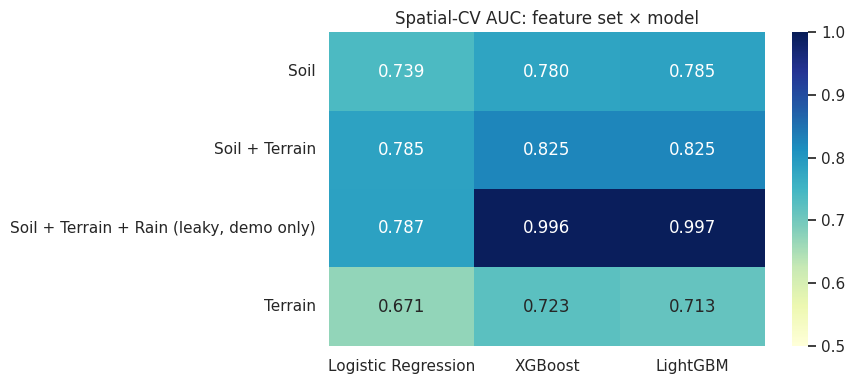

In [9]:
pivot = summary.pivot(index="feature_set", columns="model", values="AUC_mean")[MODEL_NAMES]
plt.figure(figsize=(9, 4)); sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.5, vmax=1)
plt.title("Spatial-CV AUC: feature set × model"); plt.ylabel(""); plt.xlabel(""); plt.tight_layout(); plt.show()

The results show that Soil + Terrain is the best trustworthy feature set. Adding terrain features improved every model compared to using soil features alone. Logistic Regression scored 0.785 AUC, while XGBoost and LightGBM both reached 0.825 AUC.

Step 8 – Is the difference between models real?
Paired Wilcoxon signed-rank test on the 5 per-fold AUCs, Bonferroni-corrected for 3 comparisons. **Note:** with only 5 folds the smallest possible two-sided p-value is 0.0625, so significance at 0.05 is mathematically impossible. Report the direction and size of the difference, and say this limitation in the report.

Step 8: Statistical significance test

I use a paired Wilcoxon signed-rank test to see if the differences in model scores are statistically significant. I apply a Bonferroni correction because I am making three comparisons.

In [10]:
MAIN = "Soil + Terrain"
sub = per_fold[per_fold.feature_set == MAIN].pivot(index="fold", columns="model", values="auc")
pairs = [("XGBoost", "Logistic Regression"), ("LightGBM", "Logistic Regression"), ("XGBoost", "LightGBM")]
rows = []
for a, b in pairs:
    stat, p = wilcoxon(sub[a], sub[b])
    rows.append(dict(comparison=f"{a} vs {b}", mean_AUC_diff=(sub[a]-sub[b]).mean(), folds_where_first_better=int((sub[a]>sub[b]).sum()),
                     p_raw=p, p_bonferroni=min(1, p*len(pairs))))
pd.DataFrame(rows).round(4)

,comparison,mean_AUC_diff,folds_where_first_better,p_raw,p_bonferroni
0,XGBoost vs Logistic Regression,0.0395,5,0.0625,0.1875
1,LightGBM vs Logistic Regression,0.0398,4,0.1250,0.3750
2,XGBoost vs LightGBM,-0.0003,2,1.0000,1.0000


The test shows a mean AUC difference of about 0.04 when comparing XGBoost and LightGBM to Logistic Regression. However, because we only have 5 folds, the minimum possible p-value is 0.0625. This means we cannot achieve statistical significance at the 0.05 level.

***Step 9 – Choose the threshold (target: recall ≥ 0.80)***
In a warning system a missed landslide costs more than a false alarm, so we pick the **highest threshold that still gives recall ≥ 0.80**, using out-of-fold predictions of the best model.

Step 9: Choose probability threshold

I want to find a threshold that prioritizes catching actual landslides. I look for the highest threshold that still keeps the recall rate at or above 0.80 using the LightGBM model.

In [11]:
best_name = summary[summary.feature_set == MAIN].sort_values("AUC_mean", ascending=False).iloc[0]["model"]
print("Best model on", MAIN, "->", best_name)
p_best = oof[(MAIN, best_name)]

rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (p_best >= t).astype(int)
    rows.append(dict(threshold=round(t, 2), precision=precision_score(y, pred, zero_division=0),
                     recall=recall_score(y, pred), f1=f1_score(y, pred)))
thr = pd.DataFrame(rows).round(3)
ok = thr[thr.recall >= 0.80]
THRESHOLD = float(ok.threshold.max()) if len(ok) else float(thr.sort_values("f1").iloc[-1].threshold)
print("Selected threshold:", THRESHOLD)
thr

Best model on Soil + Terrain -> LightGBM
Selected threshold: 0.45


,threshold,precision,recall,f1
0,0.10,0.609,0.960,0.746
1,0.15,0.633,0.939,0.756
2,0.20,0.672,0.923,0.777
3,0.25,0.701,0.896,0.786
4,0.30,0.709,0.871,0.782
5,0.35,0.729,0.852,0.785
6,0.40,0.737,0.825,0.778
7,0.45,0.748,0.800,0.773
8,0.50,0.746,0.766,0.756
9,0.55,0.759,0.743,0.751


I selected a threshold of 0.45. This choice gives us a recall of 0.80 and a precision of 0.75, which balances safety and false alarms.

***Step 10 – Five risk tiers***:
Cut the probability into Very Low / Low / Moderate / High / Very High (this is the output the Decision Support component will consume).

Step 10: Map risk tiers

I group the out-of-fold probability scores into five risk levels. Then I calculate the actual landslide rate in each group to see if the risk levels make sense.

,n,landslides,landslide_rate
risk_level,,,
Very Low,300,37,0.12
Low,122,47,0.39
Moderate,101,62,0.61
High,186,132,0.71
Very High,249,201,0.81


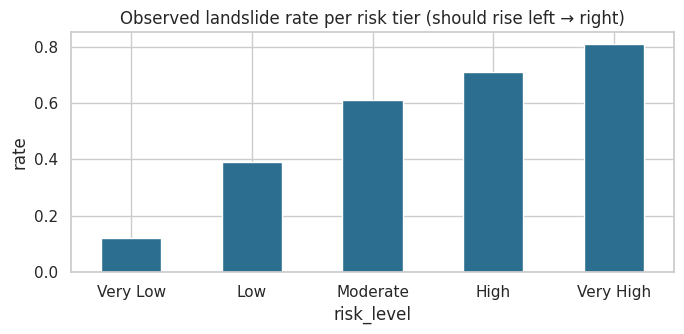

In [12]:
bins   = [-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf]
labels = ["Very Low", "Low", "Moderate", "High", "Very High"]
res = df[["lat", "lon", "dynamic_label"]].copy()
res["probability"] = p_best
res["risk_level"]  = pd.cut(res.probability, bins=bins, labels=labels)
tier = (res.groupby("risk_level", observed=False)["dynamic_label"]
        .agg(n="size", landslides="sum").assign(landslide_rate=lambda d: (d.landslides / d.n).round(2)))
display(tier)
tier["landslide_rate"].plot(kind="bar", figsize=(7, 3.5), color="#2b6e8f", title="Observed landslide rate per risk tier (should rise left → right)")
plt.ylabel("rate"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

The chart shows that the observed landslide rate rises consistently as the risk tier increases. The rate is about 12% in the Very Low tier and rises to about 81% in the Very High tier. These levels rank landslide risk well, even though they are not exact real-world probabilities.

Save the result to Dir

Step 11: Save final outputs

I save the performance summary, the fold scores, the threshold table, and the risk predictions as CSV files. These tables can be used in our final report.

In [13]:
summary.to_csv(OUT / "model_comparison_spatial_cv.csv", index=False)
per_fold.to_csv(OUT / "per_fold_auc.csv", index=False)
thr.to_csv(OUT / "threshold_table.csv", index=False)
res.to_csv(OUT / "oof_predictions_risk_tiers.csv", index=False)
print("Saved to", OUT.resolve())

Saved to /content/outputs/tables
